In [11]:
%pip install "geopandas[all]" -q

Note: you may need to restart the kernel to use updated packages.


In [12]:
from pathlib import Path

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

output_dir_vis = Path("./vis")
output_dir_vis.mkdir(exist_ok=True)

In [15]:
housing_production = pd.read_csv("data/Housing_Production_-_2005-present_20261007.csv")
housing_production

,BPA,Address,Description,PTS Existing Units,PTS Proposed Units,Proposed Units,Net Units,Net Units Completed,ADU/Legalization Units,First Completion Date,...,Plan Area,Form No.,Permit Type,Issued Date,Authorization Date,Zoning District,Project Affordability Type,BMR Reporting Year,BlockLot,PPTS Project ID
0,1801Wedemeyer,1801 Wedemeyer St,PRESIDIO LANDMARK 100 1-BR; 54 2-BR (Federal l...,0,NaN,154,154,154,0,06/30/2010,...,NaN,3,Site Permit,04/27/2007,04/27/2007,P,NaN,2010,1300001,NaN
1,20000109571,360 BENTON AV,"TO ERECT A NEW 3 STORY, 2 UNIT RESIDENTIAL BUI...",0,2.0,2,2,2,0,12/08/2008,...,NaN,2,Site Permit,08/29/2006,08/29/2006,RH-2,NaN,2008,5828012,2007.0150
2,20000112863,340 BENTON AV,TO ERECT A NEW 3 STORY 2 FAMILY DWELLING RESID...,0,2.0,2,2,2,0,12/08/2008,...,NaN,2,Site Permit,08/29/2006,08/29/2006,RH-2,NaN,2008,5828011,NaN
3,20000112908,505 KIRKHAM ST,ERECT 4 STORY 2 FAMILY DWELLING UNIT,0,2.0,2,2,2,0,11/15/2005,...,NaN,2,Site Permit,08/31/2004,09/01/2004,RH-2,NaN,2005,1855045,2003.0545
4,20000118277,1810 POLK ST,"TO ERECT 12 DWELLING UNITS, 4 STORIES, RESIDEN...",0,12.0,12,12,12,0,09/29/2006,...,NaN,2,Full Building Permit,01/05/2005,01/05/2005,NCD-POLK,Incl: On-Site BMR,2006,0597016,2000.051
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6144,9924082S,871 JAMESTOWN AV,BLDG #6 - ERECT A 3 STORIES OF EIGHTEEN UNITS ...,0,18.0,18,18,18,0,08/20/2014,...,NaN,2,Site Permit,03/28/2006,08/16/2006,RH-2,100% Affordable,2014,4991277,1999.233
6145,9925758S,981 GREENWICH ST,ERECT A THREE STORY THREE UNIT RESIDENTIAL BLDG,0,3.0,3,3,3,0,07/21/2005,...,NaN,2,Site Permit,08/02/2001,08/03/2001,RM-1,NaN,2005,0092044,2002.0792
6146,9927159S,380 BENTON AV,"TO ERECT A NEW 3 STORY, 2 UNIT RESIDENTIAL BUI...",0,2.0,2,2,2,0,12/08/2008,...,NaN,2,Site Permit,08/29/2006,08/31/2006,RH-2,NaN,2008,5828013,2007.0151
6147,Academe 198,198 McAllister St,SF Law graduate student housing – Majority of ...,0,NaN,657,657,657,0,08/15/2023,...,NaN,1,Full Building Permit,NaN,02/01/2023,P,NaN,2023,0348009,2025-008348PRX


In [16]:
housing_production.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6149 entries, 0 to 6148
Data columns (total 31 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   BPA                         6149 non-null   object 
 1   Address                     6149 non-null   object 
 2   Description                 6149 non-null   object 
 3   PTS Existing Units          6149 non-null   int64  
 4   PTS Proposed Units          6142 non-null   float64
 5   Proposed Units              6149 non-null   int64  
 6   Net Units                   6149 non-null   int64  
 7   Net Units Completed         6149 non-null   int64  
 8   ADU/Legalization Units      6149 non-null   int64  
 9   First Completion Date       6149 non-null   object 
 10  Latest Completion Date      6149 non-null   object 
 11  Extremely Low Income        6149 non-null   int64  
 12  Very Low Income             6149 non-null   int64  
 13  Low Income                  6149 

In [17]:
dates = pd.to_datetime(housing_production["First Completion Date"])
housing_production_2005_2025 = housing_production[(dates >= "2005-01-01") & (dates <= "2025-12-31")]
housing_production_2005_2025

,BPA,Address,Description,PTS Existing Units,PTS Proposed Units,Proposed Units,Net Units,Net Units Completed,ADU/Legalization Units,First Completion Date,...,Plan Area,Form No.,Permit Type,Issued Date,Authorization Date,Zoning District,Project Affordability Type,BMR Reporting Year,BlockLot,PPTS Project ID
0,1801Wedemeyer,1801 Wedemeyer St,PRESIDIO LANDMARK 100 1-BR; 54 2-BR (Federal l...,0,NaN,154,154,154,0,06/30/2010,...,NaN,3,Site Permit,04/27/2007,04/27/2007,P,NaN,2010,1300001,NaN
1,20000109571,360 BENTON AV,"TO ERECT A NEW 3 STORY, 2 UNIT RESIDENTIAL BUI...",0,2.0,2,2,2,0,12/08/2008,...,NaN,2,Site Permit,08/29/2006,08/29/2006,RH-2,NaN,2008,5828012,2007.0150
2,20000112863,340 BENTON AV,TO ERECT A NEW 3 STORY 2 FAMILY DWELLING RESID...,0,2.0,2,2,2,0,12/08/2008,...,NaN,2,Site Permit,08/29/2006,08/29/2006,RH-2,NaN,2008,5828011,NaN
3,20000112908,505 KIRKHAM ST,ERECT 4 STORY 2 FAMILY DWELLING UNIT,0,2.0,2,2,2,0,11/15/2005,...,NaN,2,Site Permit,08/31/2004,09/01/2004,RH-2,NaN,2005,1855045,2003.0545
4,20000118277,1810 POLK ST,"TO ERECT 12 DWELLING UNITS, 4 STORIES, RESIDEN...",0,12.0,12,12,12,0,09/29/2006,...,NaN,2,Full Building Permit,01/05/2005,01/05/2005,NCD-POLK,Incl: On-Site BMR,2006,0597016,2000.051
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6144,9924082S,871 JAMESTOWN AV,BLDG #6 - ERECT A 3 STORIES OF EIGHTEEN UNITS ...,0,18.0,18,18,18,0,08/20/2014,...,NaN,2,Site Permit,03/28/2006,08/16/2006,RH-2,100% Affordable,2014,4991277,1999.233
6145,9925758S,981 GREENWICH ST,ERECT A THREE STORY THREE UNIT RESIDENTIAL BLDG,0,3.0,3,3,3,0,07/21/2005,...,NaN,2,Site Permit,08/02/2001,08/03/2001,RM-1,NaN,2005,0092044,2002.0792
6146,9927159S,380 BENTON AV,"TO ERECT A NEW 3 STORY, 2 UNIT RESIDENTIAL BUI...",0,2.0,2,2,2,0,12/08/2008,...,NaN,2,Site Permit,08/29/2006,08/31/2006,RH-2,NaN,2008,5828013,2007.0151
6147,Academe 198,198 McAllister St,SF Law graduate student housing – Majority of ...,0,NaN,657,657,657,0,08/15/2023,...,NaN,1,Full Building Permit,NaN,02/01/2023,P,NaN,2023,0348009,2025-008348PRX


In [18]:
housing_production_filtered = housing_production_2005_2025[
    housing_production_2005_2025["Net Units Completed"].notna() & 
    (housing_production_2005_2025["Net Units Completed"] >= 0)
]
housing_production_filtered

,BPA,Address,Description,PTS Existing Units,PTS Proposed Units,Proposed Units,Net Units,Net Units Completed,ADU/Legalization Units,First Completion Date,...,Plan Area,Form No.,Permit Type,Issued Date,Authorization Date,Zoning District,Project Affordability Type,BMR Reporting Year,BlockLot,PPTS Project ID
0,1801Wedemeyer,1801 Wedemeyer St,PRESIDIO LANDMARK 100 1-BR; 54 2-BR (Federal l...,0,NaN,154,154,154,0,06/30/2010,...,NaN,3,Site Permit,04/27/2007,04/27/2007,P,NaN,2010,1300001,NaN
1,20000109571,360 BENTON AV,"TO ERECT A NEW 3 STORY, 2 UNIT RESIDENTIAL BUI...",0,2.0,2,2,2,0,12/08/2008,...,NaN,2,Site Permit,08/29/2006,08/29/2006,RH-2,NaN,2008,5828012,2007.0150
2,20000112863,340 BENTON AV,TO ERECT A NEW 3 STORY 2 FAMILY DWELLING RESID...,0,2.0,2,2,2,0,12/08/2008,...,NaN,2,Site Permit,08/29/2006,08/29/2006,RH-2,NaN,2008,5828011,NaN
3,20000112908,505 KIRKHAM ST,ERECT 4 STORY 2 FAMILY DWELLING UNIT,0,2.0,2,2,2,0,11/15/2005,...,NaN,2,Site Permit,08/31/2004,09/01/2004,RH-2,NaN,2005,1855045,2003.0545
4,20000118277,1810 POLK ST,"TO ERECT 12 DWELLING UNITS, 4 STORIES, RESIDEN...",0,12.0,12,12,12,0,09/29/2006,...,NaN,2,Full Building Permit,01/05/2005,01/05/2005,NCD-POLK,Incl: On-Site BMR,2006,0597016,2000.051
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6144,9924082S,871 JAMESTOWN AV,BLDG #6 - ERECT A 3 STORIES OF EIGHTEEN UNITS ...,0,18.0,18,18,18,0,08/20/2014,...,NaN,2,Site Permit,03/28/2006,08/16/2006,RH-2,100% Affordable,2014,4991277,1999.233
6145,9925758S,981 GREENWICH ST,ERECT A THREE STORY THREE UNIT RESIDENTIAL BLDG,0,3.0,3,3,3,0,07/21/2005,...,NaN,2,Site Permit,08/02/2001,08/03/2001,RM-1,NaN,2005,0092044,2002.0792
6146,9927159S,380 BENTON AV,"TO ERECT A NEW 3 STORY, 2 UNIT RESIDENTIAL BUI...",0,2.0,2,2,2,0,12/08/2008,...,NaN,2,Site Permit,08/29/2006,08/31/2006,RH-2,NaN,2008,5828013,2007.0151
6147,Academe 198,198 McAllister St,SF Law graduate student housing – Majority of ...,0,NaN,657,657,657,0,08/15/2023,...,NaN,1,Full Building Permit,NaN,02/01/2023,P,NaN,2023,0348009,2025-008348PRX


In [19]:
housing_production_filtered["BlockLot"]

0       1300001
1       5828012
2       5828011
3       1855045
4       0597016
         ...   
6144    4991277
6145    0092044
6146    5828013
6147    0348009
6148    7314001
Name: BlockLot, Length: 4818, dtype: object

In [20]:
housing_production_filtered.to_csv('housing_production_filtered.csv', index=False)

In [21]:
neighborhood_production = (
    housing_production_filtered.groupby("Analysis Neighborhood")["Net Units Completed"]
    .sum()
    .reset_index()
)

print(neighborhood_production.sort_values(by="Net Units Completed", ascending=False))

             Analysis Neighborhood  Net Units Completed
31                 South of Market                10581
5   Financial District/South Beach                 9726
17                     Mission Bay                 7812
16                         Mission                 5771
33                      Tenderloin                 4774
26                    Potrero Hill                 3923
0            Bayview Hunters Point                 3289
8                     Hayes Valley                 2335
38                Western Addition                 1431
34                 Treasure Island                  982
18                        Nob Hill                  860
22                   Outer Mission                  826
2              Castro/Upper Market                  672
32                 Sunset/Parkside                  581
29                    Russian Hill                  555
15                          Marina                  506
23                  Outer Richmond              

In [53]:
import plotly.express as px

# 1. Group your filtered data by neighborhood
neighborhood_data = (
    housing_production_filtered.groupby("Analysis Neighborhood")["Net Units Completed"]
    .sum()
    .reset_index()
)

# 2. Plot using Plotly's built-in SF neighborhood support or a choropleth
# (Plotly has built-in mapping capabilities for standard regions)
print(neighborhood_data.head())

   Analysis Neighborhood  Net Units Completed
0  Bayview Hunters Point                 3289
1         Bernal Heights                  433
2    Castro/Upper Market                  672
3              Chinatown                  239
4              Excelsior                  473


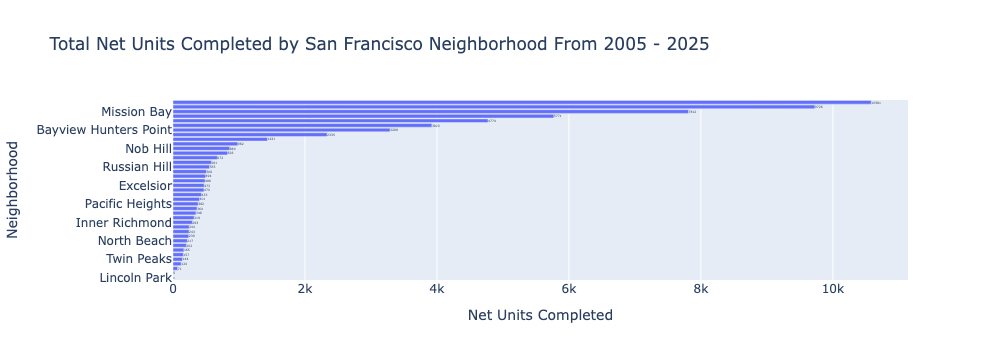

In [57]:
neighborhood_data_sorted = neighborhood_data.sort_values(by="Net Units Completed", ascending=True)

fig = px.bar(
    neighborhood_data_sorted,
    x="Net Units Completed",
    y="Analysis Neighborhood",
    orientation="h",
    title="Total Net Units Completed by San Francisco Neighborhood From 2005 - 2025",
    text="Net Units Completed"
)

fig.update_layout(yaxis_title="Neighborhood", xaxis_title="Net Units Completed")
fig.show()

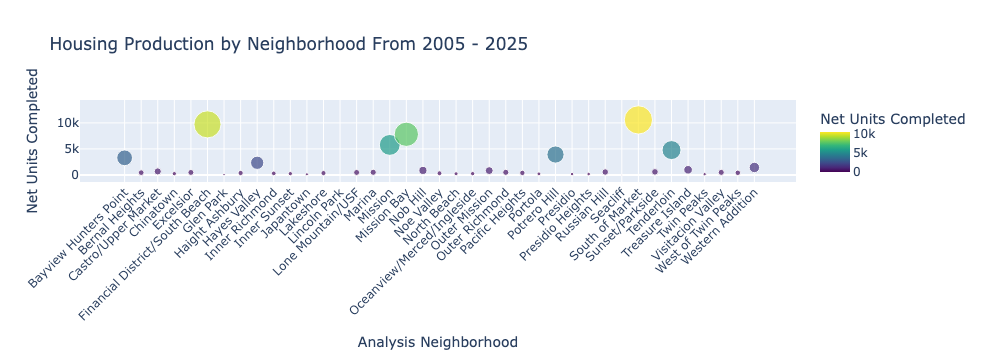

In [58]:
fig = px.scatter(
    neighborhood_data,
    x="Analysis Neighborhood",
    y="Net Units Completed",
    size="Net Units Completed",
    color="Net Units Completed",
    title="Housing Production by Neighborhood From 2005 - 2025",
    color_continuous_scale="Viridis"
)

fig.update_layout(xaxis_tickangle=-45)
fig.show()